## **What affects students' exam scores the most?**

In [ ]:
# Import necessary libraries
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("kundanbedmutha/exam-score-prediction-dataset")

print("Path to dataset files:", path)

100%|██████████| 318k/318k [00:00<00:00, 63.7MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/kundanbedmutha/exam-score-prediction-dataset/versions/2


In [ ]:
df = pd.read_csv(path + '/Exam_Score_Prediction.csv')
df.head() #View the data

,student_id,age,gender,course,study_hours,class_attendance,internet_access,sleep_hours,sleep_quality,study_method,facility_rating,exam_difficulty,exam_score
0,1,17,male,diploma,2.78,92.9,yes,7.4,poor,coaching,low,hard,58.9
1,2,23,other,bca,3.37,64.8,yes,4.6,average,online videos,medium,moderate,54.8
2,3,22,male,b.sc,7.88,76.8,yes,8.5,poor,coaching,high,moderate,90.3
3,4,20,other,diploma,0.67,48.4,yes,5.8,average,online videos,low,moderate,29.7
4,5,20,female,diploma,0.89,71.6,yes,9.8,poor,coaching,low,moderate,43.7


In [ ]:
print(df.shape) #Check the shape(rows,columns)
print(df.dtypes) #data type

(20000, 13)
student_id            int64
age                   int64
gender               object
course               object
study_hours         float64
class_attendance    float64
internet_access      object
sleep_hours         float64
sleep_quality        object
study_method         object
facility_rating      object
exam_difficulty      object
exam_score          float64
dtype: object


In [ ]:
df.info() #View dtypes

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   student_id        20000 non-null  int64  
 1   age               20000 non-null  int64  
 2   gender            20000 non-null  object 
 3   course            20000 non-null  object 
 4   study_hours       20000 non-null  float64
 5   class_attendance  20000 non-null  float64
 6   internet_access   20000 non-null  object 
 7   sleep_hours       20000 non-null  float64
 8   sleep_quality     20000 non-null  object 
 9   study_method      20000 non-null  object 
 10  facility_rating   20000 non-null  object 
 11  exam_difficulty   20000 non-null  object 
 12  exam_score        20000 non-null  float64
dtypes: float64(4), int64(2), object(7)
memory usage: 2.0+ MB


In [ ]:
df.describe(include='all') #statistical summary of the data

,student_id,age,gender,course,study_hours,class_attendance,internet_access,sleep_hours,sleep_quality,study_method,facility_rating,exam_difficulty,exam_score
count,20000.000000,20000.000000,20000,20000,20000.000000,20000.000000,20000,20000.00000,20000,20000,20000,20000,20000.000000
unique,NaN,NaN,3,7,NaN,NaN,2,NaN,3,5,3,3,NaN
top,NaN,NaN,other,bca,NaN,NaN,yes,NaN,average,self-study,medium,moderate,NaN
freq,NaN,NaN,6726,2902,NaN,NaN,16988,NaN,6694,4079,6760,9878,NaN
mean,10000.504600,20.473300,NaN,NaN,4.007604,70.017365,NaN,7.00856,NaN,NaN,NaN,NaN,62.513225
std,5773.654959,2.284458,NaN,NaN,2.308313,17.282262,NaN,1.73209,NaN,NaN,NaN,NaN,18.908491
min,1.000000,17.000000,NaN,NaN,0.080000,40.600000,NaN,4.10000,NaN,NaN,NaN,NaN,19.599000
25%,5000.750000,18.000000,NaN,NaN,2.000000,55.100000,NaN,5.50000,NaN,NaN,NaN,NaN,48.800000
50%,10000.500000,20.000000,NaN,NaN,4.040000,69.900000,NaN,7.00000,NaN,NaN,NaN,NaN,62.600000
75%,15000.250000,22.000000,NaN,NaN,6.000000,85.000000,NaN,8.50000,NaN,NaN,NaN,NaN,76.300000


In [ ]:
df.isnull().sum() # Checking for missing values

,0
student_id,0
age,0
gender,0
course,0
study_hours,0
class_attendance,0
internet_access,0
sleep_hours,0
sleep_quality,0
study_method,0


In [ ]:
df.duplicated().sum() #Checking for duplicate values

np.int64(0)

## **EDA**

In [ ]:
df['exam_score'].describe() #statistical summary of the target variable

,exam_score
count,20000.000000
mean,62.513225
std,18.908491
min,19.599000
25%,48.800000
50%,62.600000
75%,76.300000
max,100.000000


In [ ]:
numeric_col = ['study_hours', 'sleep_hours', 'class_attendance', 'exam_score']

df[numeric_col].corr() # correlation between numerical variables

,study_hours,sleep_hours,class_attendance,exam_score
study_hours,1.000000,-0.004533,-0.001645,0.717788
sleep_hours,-0.004533,1.000000,0.007187,0.133222
class_attendance,-0.001645,0.007187,1.000000,0.308850
exam_score,0.717788,0.133222,0.308850,1.000000


### Average exam score by gender

In [ ]:
df.groupby('gender')['exam_score'].mean()

,exam_score
gender,
female,62.582145
male,62.397480
other,62.561023


### Average exam score by study method

In [ ]:
df.groupby('study_method')['exam_score'].mean()

,exam_score
study_method,
coaching,68.550963
group study,60.967482
mixed,64.242879
online videos,60.151694
self-study,58.729919


### Average exam score by internet access

In [ ]:
df.groupby('internet_access')['exam_score'].mean()

,exam_score
internet_access,
no,62.864663
yes,62.450914


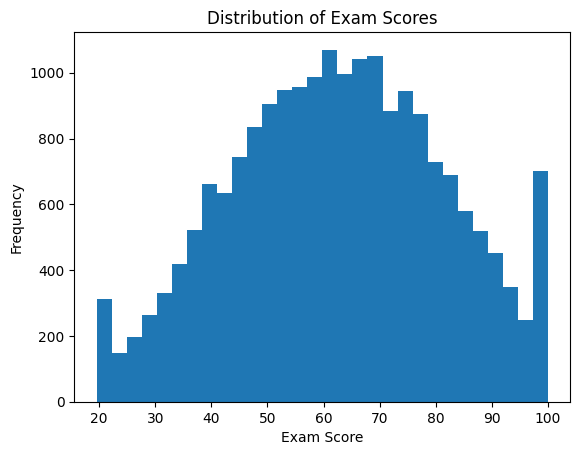

In [ ]:
plt.hist(df['exam_score'], bins=30)
plt.xlabel('Exam Score')
plt.ylabel('Frequency')
plt.title('Distribution of Exam Scores')
plt.show()

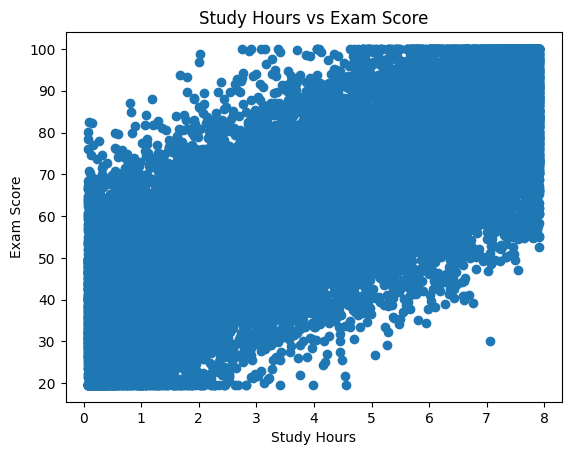

In [ ]:
plt.scatter(df['study_hours'], df['exam_score'])
plt.xlabel('Study Hours')
plt.ylabel('Exam Score')
plt.title('Study Hours vs Exam Score')
plt.show()

## The dataset was explored using descriptive statistics, group summaries, and visualizations. The correlation analysis suggested that study hours had the strongest positive relationship with exam scores. Students with greater study hours generally achieved higher scores, while variables such as internet access showed a weaker relationship.

## **Hypothesis Testing**

## Do students who study more score significantly higher than those who study less?

We'll split students into:

* Low study hours: Less than 4 hours/day
* High study hours: 4 hours/day or more

In [ ]:
low_study = df[df['study_hours'] < 4]['exam_score']
high_study = df[df['study_hours'] >= 4]['exam_score']

* Null Hypothesis (H₀): There is no significant difference in the average exam scores of the two groups.
* Alternative Hypothesis (H₁): There is a significant difference in the average exam scores of the two groups.

In [ ]:
from scipy.stats import ttest_ind

t_stats, p_value = ttest_ind(high_study, low_study)
print('T-stats:', t_stats)
print('P-value:', p_value)

T-stats: 113.5087251544137
P-value: 0.0


In [ ]:
alpha = 0.05

if p_value < alpha:
    print("Reject the null hypothesis.")
    print("Study hours have a significant effect on exam scores.")
else:
    print("Fail to reject the null hypothesis.")
    print("There is no significant evidence that study hours affect exam scores.")

Reject the null hypothesis.
Study hours have a significant effect on exam scores.


### **Conclusion**

Since:

P-value < 0.05 ✅

we reject the null hypothesis.

This means there is strong statistical evidence that students who study 4 or more hours per day have different (and likely higher) average exam scores than students who study less than 4 hours per day.

The very large t-statistic (113.51) suggests the difference between the two groups is substantial.

## **Recommendations**
* Students should maintain consistent study habits.
* Schools can encourage effective time management and study schedules.